# 08 - Score Scaling & Scorecard

Turn the logistic regression from `06_modelling` into a points-based credit score.

**Scaling** (Siddiqi): `score = offset + factor × ln(odds)`, with `odds = P(good) / P(bad)`,
`factor = PDO / ln 2`, `offset = base_score − factor × ln(base_odds)`.

| Parameter | Value | Meaning |
|---|---|---|
| Base score | 600 | Score at the base odds |
| Base odds | 50:1 | Good:bad odds at 600 (PD ≈ 1.96%) |
| PDO | 20 | Every +20 points the good:bad odds double |

A higher score means lower risk. Steps:

1. Scorecard table: points for every bin of every feature.
2. **Direction check**: coefficient signs and points vs bad rate, plus a business-sense review.
3. Scores on train/test and consistency check (sum of points = score from PD).
4. Validation: calibration by decile, PSI train vs test, score distribution.
5. Cut-off table: approval rate vs bad rate.

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import calibration_table, psi
from src.model import predict_pd
from src.scorecard import (
    apply_scorecard,
    cutoff_table,
    neutral_points,
    pd_to_score,
    points_direction,
    scaling_params,
    scorecard_table,
)
from src.woe import bin_frame

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

BASE_SCORE = 600
BASE_ODDS = 50
PDO = 20

# Chart colors: categorical slots 1-2, muted ink for reference lines / text
BLUE, ORANGE = "#2a78d6", "#eb6834"
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 2. Load model, WoE tables and data

In [2]:
with open(OUTPUT_DIR / "logit_model.pkl", "rb") as f:
    model = pickle.load(f)
with open(OUTPUT_DIR / "woe_tables_final.pkl", "rb") as f:
    woe_tables = pickle.load(f)
with open(OUTPUT_DIR / "woe_spec_final.pkl", "rb") as f:
    woe_spec = pickle.load(f)
features = pd.read_csv(OUTPUT_DIR / "model_features.csv")["feature"].tolist()

intercept = model.params["const"]
coefs = model.params.drop("const")[features]

woe_train = pd.read_pickle(DATA_DIR / "woe_train.pkl")
woe_test = pd.read_pickle(DATA_DIR / "woe_test.pkl")
y_train, y_test = woe_train["TARGET"], woe_test["TARGET"]
pd_train = predict_pd(model, woe_train[features])
pd_test = predict_pd(model, woe_test[features])

factor, offset = scaling_params(BASE_SCORE, BASE_ODDS, PDO)
print(f"factor = {factor:.4f} | offset = {offset:.4f} | intercept = {intercept:.4f}")

factor = 28.8539 | offset = 487.1229 | intercept = -2.4358


## 3. Scorecard table

Intercept and offset are spread evenly over the features; a customer's score is the sum of the points of their bins. Bins unseen in training get the neutral points (WoE = 0, average risk).

In [3]:
card = scorecard_table(coefs, intercept, woe_tables, factor, offset)
neutral = neutral_points(coefs, intercept, factor, offset)
print(f"{len(card)} rows | neutral points per feature = {neutral:.2f}")
card.assign(points=card["points"].round(0).astype(int)).round(3)

131 rows | neutral points per feature = 34.84


,feature,bin,share,bad_rate,woe,points
0,EXT_SOURCE_3,"(-inf, 0.2276]",0.080,0.199,-1.041,9
1,EXT_SOURCE_3,"(0.2276, 0.3297]",0.080,0.128,-0.511,22
2,EXT_SOURCE_3,"(0.3297, 0.4084]",0.081,0.098,-0.210,30
3,EXT_SOURCE_3,"(0.4084, 0.4758]",0.081,0.079,0.018,35
4,EXT_SOURCE_3,"(0.4758, 0.5353]",0.079,0.062,0.287,42
...,...,...,...,...,...,...
126,OWN_CAR_AGE,"(9, 12]",0.043,0.076,0.060,36
127,OWN_CAR_AGE,"(12, 14]",0.030,0.088,-0.096,33
128,OWN_CAR_AGE,"(14, 17]",0.032,0.089,-0.106,33
129,OWN_CAR_AGE,"(17, inf]",0.061,0.093,-0.157,32


## 4. Direction check

1. **Coefficient sign**: with WoE = ln(%good / %bad), every coefficient must be negative.
2. **Points vs bad rate**: within each feature, bins with a higher bad rate must get fewer points (Spearman < 0).
3. **Business sense**: read the lowest- and highest-point bins of each feature and judge whether the direction makes sense.

In [4]:
sign_check = coefs.to_frame("coef").assign(negative=coefs < 0)
assert sign_check["negative"].all(), "Some coefficients are not negative"

direction = points_direction(card)
assert direction["consistent"].all(), "Points do not fall with bad rate for some features"
direction.join(sign_check).round(3)

,min_points,max_points,range,spearman,consistent,coef,negative
EXT_SOURCE_3,9.379,58.273,48.894,-1.0,True,-0.848,True
EXT_SOURCE_2,14.918,57.381,42.462,-1.0,True,-0.739,True
EXT_SOURCE_1,21.733,52.767,31.033,-1.0,True,-0.519,True
NAME_EDUCATION_TYPE,29.323,41.631,12.308,-1.0,True,-0.545,True
YEARS_EMPLOYED,31.336,40.767,9.431,-1.0,True,-0.326,True
OWN_CAR_AGE,32.111,41.533,9.422,-1.0,True,-0.603,True
OCCUPATION_TYPE,31.516,40.175,8.659,-1.0,True,-0.313,True
ORGANIZATION_TYPE,30.989,38.703,7.714,-1.0,True,-0.306,True
REGION_RATING_CLIENT_W_CITY,31.756,39.125,7.369,-1.0,True,-0.275,True
FLAG_DOCUMENT_3,32.951,40.278,7.327,-1.0,True,-0.657,True


In [5]:
# Business-sense review: worst and best bin of each feature (feature order = weight in the score)
def extremes(g: pd.DataFrame) -> pd.Series:
    worst, best = g.loc[g["points"].idxmin()], g.loc[g["points"].idxmax()]
    return pd.Series({
        "worst_bin": worst["bin"], "worst_bad_rate": worst["bad_rate"], "worst_points": worst["points"],
        "best_bin": best["bin"], "best_bad_rate": best["bad_rate"], "best_points": best["points"],
    })


review = card.groupby("feature", sort=False)[["bin", "bad_rate", "points"]].apply(extremes)
review.loc[direction.index].round(3)

,worst_bin,worst_bad_rate,worst_points,best_bin,best_bad_rate,best_points
feature,,,,,,
EXT_SOURCE_3,"(-inf, 0.2276]",0.199,9.379,"(0.749, inf]",0.033,58.273
EXT_SOURCE_2,"(-inf, 0.2153]",0.183,14.918,"(0.722, inf]",0.030,57.381
EXT_SOURCE_1,"(-inf, 0.2117]",0.174,21.733,"(0.7869, inf]",0.026,52.767
NAME_EDUCATION_TYPE,Lower secondary,0.111,29.323,Higher education,0.054,41.631
YEARS_EMPLOYED,"(-inf, 1.69]",0.113,31.336,"(14.62, inf]",0.045,40.767
OWN_CAR_AGE,"(17, inf]",0.093,32.111,"(-inf, 6]",0.056,41.533
OCCUPATION_TYPE,Drivers,0.113,31.516,Accountants,0.046,40.175
ORGANIZATION_TYPE,Construction,0.119,30.989,XNA,0.054,38.703
REGION_RATING_CLIENT_W_CITY,3,0.115,31.756,1,0.049,39.125


## 5. Scores and consistency check

Score from summed points (raw data → bins → points) must equal the score from the model PD.

In [6]:
score_train = pd_to_score(pd_train, factor, offset)
score_test = pd_to_score(pd_test, factor, offset)

test_raw = pd.read_pickle(DATA_DIR / "test.pkl")
binned_test = bin_frame(test_raw, {f: woe_spec[f] for f in features})
score_from_card = apply_scorecard(binned_test, card, neutral)

max_diff = (score_from_card - score_test.loc[score_from_card.index]).abs().max()
print(f"Max |points sum - PD score| on test: {max_diff:.2e}")
assert max_diff < 1e-6

pd.DataFrame({"train": score_train.describe(), "test": score_test.describe()}).round(1)

Max |points sum - PD score| on test: 3.41e-13


,train,test
count,246008.0,61503.0
mean,567.0,567.0
std,26.5,26.4
min,474.3,474.7
25%,548.7,548.7
50%,567.3,567.6
75%,585.6,585.5
max,666.2,657.0


## 6. Score distribution (test)

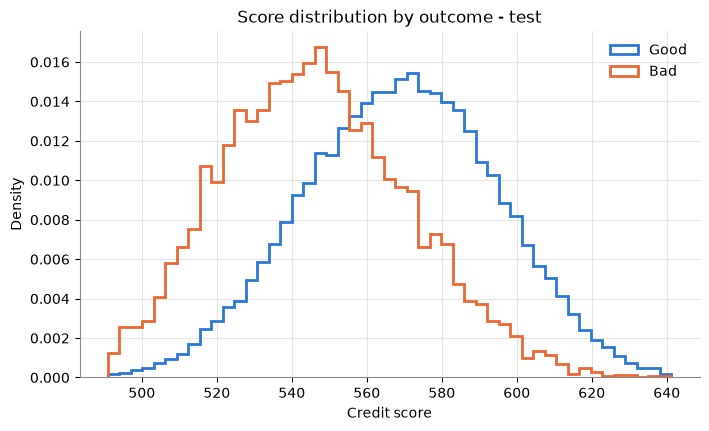

In [7]:
bins = np.linspace(score_test.quantile(0.001), score_test.quantile(0.999), 50)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(score_test[y_test == 0], bins=bins, density=True, histtype="step", color=BLUE, linewidth=2, label="Good")
ax.hist(score_test[y_test == 1], bins=bins, density=True, histtype="step", color=ORANGE, linewidth=2, label="Bad")
ax.set(xlabel="Credit score", ylabel="Density", title="Score distribution by outcome - test")
ax.legend(frameon=False)
fig.savefig(OUTPUT_DIR / "score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Calibration and stability

- **Calibration**: mean predicted PD vs observed default rate per decile (`ratio` ≈ 1 is good).
- **PSI** of the score, train vs test: < 0.1 stable, 0.1–0.25 monitor, > 0.25 shift. (Train and test come from the same random split, so PSI should be near 0; real monitoring compares against new applications.)

In [8]:
calib = calibration_table(y_test, pd_test, n_bins=10)
calib.style.format({"mean_pd": "{:.2%}", "bad_rate": "{:.2%}", "ratio": "{:.2f}"})

,n,mean_pd,bad_rate,ratio
band,,,,
1,6151,24.51%,24.96%,1.02
2,6150,14.36%,14.28%,0.99
3,6150,10.61%,10.99%,1.04
4,6150,8.23%,8.15%,0.99
5,6151,6.51%,6.31%,0.97
6,6150,5.20%,5.02%,0.97
7,6150,4.12%,4.13%,1.00
8,6150,3.20%,2.91%,0.91
9,6150,2.34%,2.52%,1.08


In [9]:
score_psi = psi(score_train, score_test)
print(f"PSI (score, train vs test) = {score_psi:.4f}")

PSI (score, train vs test) = 0.0002


## 8. Cut-off table (test)

Approve customers with `score >= cutoff`. Each row shows how many are approved, the default rate among them, and the share of all bads turned away.

In [10]:
cutoffs = list(range(480, 621, 10))
cuts = cutoff_table(y_test, score_test, cutoffs)
cuts.style.format({"approval_rate": "{:.1%}", "bad_rate_approved": "{:.2%}", "bads_rejected_pct": "{:.1%}"})

,approval_rate,bad_rate_approved,bads_rejected_pct
cutoff,,,
480,100.0%,8.07%,0.0%
490,99.9%,8.03%,0.6%
500,99.5%,7.89%,2.7%
510,98.5%,7.62%,7.0%
520,96.0%,7.09%,15.7%
530,91.5%,6.37%,27.8%
540,84.2%,5.55%,42.1%
550,73.6%,4.62%,57.9%
560,60.7%,3.79%,71.5%


## 9. Save artifacts

In [11]:
card.to_csv(OUTPUT_DIR / "scorecard.csv", index=False)
pd.Series({"base_score": BASE_SCORE, "base_odds": BASE_ODDS, "pdo": PDO, "factor": factor,
           "offset": offset, "neutral_points": neutral, "psi_train_test": score_psi}).to_csv(OUTPUT_DIR / "score_scaling.csv")
calib.to_csv(OUTPUT_DIR / "calibration_test.csv")
cuts.to_csv(OUTPUT_DIR / "cutoff_table_test.csv")
print("Saved scorecard.csv, score_scaling.csv, calibration_test.csv, cutoff_table_test.csv, score_distribution.png")

Saved scorecard.csv, score_scaling.csv, calibration_test.csv, cutoff_table_test.csv, score_distribution.png
